<a href="https://colab.research.google.com/github/asetya/BigData/blob/master/harisdet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files

uploaded = files.upload()
for filename, content in uploaded.items():
    print(f"Processing uploaded image: {filename}")
    process_and_visualize(content, k=0.04, sigma=1.2, threshold_ratio=0.01, nms_size=5)

In [2]:
# ==============================================================================
# General Harris Corner Detector for Arbitrary Input Images
# Runs directly in Google Colab
# ==============================================================================

import io
import urllib.request
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, maximum_filter

def load_image(source):
    """
    Loads an image from a file path, a URL, or an in-memory byte buffer.
    Returns:
    - img_bgr: 3-channel BGR uint8 image for visualization
    - img_gray: Grayscale float32 image normalized to [0, 1]
    """
    if isinstance(source, bytes):
        nparr = np.frombuffer(source, np.uint8)
        img_bgr = cv2.imdecode(nparr, cv2.IMREAD_COLOR)
    elif source.startswith('http://') or source.startswith('https://'):
        req = urllib.request.Request(source, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(req) as resp:
            nparr = np.frombuffer(resp.read(), np.uint8)
            img_bgr = cv2.imdecode(nparr, cv2.IMREAD_COLOR)
    else:
        img_bgr = cv2.imread(source, cv2.IMREAD_COLOR)

    if img_bgr is None:
        raise ValueError(f"Failed to load image from source: {source}")

    # Convert to grayscale and normalize intensity to [0, 1]
    img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY).astype(np.float32) / 255.0
    return img_bgr, img_gray


def harris_corner_detector(img_gray, k=0.04, sigma=1.2, threshold_ratio=0.01, nms_size=5):
    """
    Executes the Harris Corner Detection pipeline on a grayscale image.
    """
    # 1. Gradients via Sobel operators
    Ix = cv2.Sobel(img_gray, cv2.CV_64F, 1, 0, ksize=3)
    Iy = cv2.Sobel(img_gray, cv2.CV_64F, 0, 1, ksize=3)

    # 2. Derivative products
    Ixx = Ix ** 2
    Iyy = Iy ** 2
    Ixy = Ix * Iy

    # 3. Structure tensor components via Gaussian smoothing
    Sxx = gaussian_filter(Ixx, sigma=sigma)
    Syy = gaussian_filter(Iyy, sigma=sigma)
    Sxy = gaussian_filter(Ixy, sigma=sigma)

    # 4. Corner response: R = det(M) - k * (trace(M))^2
    det_M = (Sxx * Syy) - (Sxy ** 2)
    trace_M = Sxx + Syy
    R = det_M - k * (trace_M ** 2)

    # 5. Adaptive thresholding relative to maximum positive response
    max_val = R.max()
    if max_val <= 0:
        return R, []  # Return empty if no positive curvature exists

    threshold = threshold_ratio * max_val
    R_thresh = np.where(R > threshold, R, 0)

    # 6. Non-Maximum Suppression (NMS)
    local_max = maximum_filter(R_thresh, size=nms_size)
    is_corner = (R_thresh == local_max) & (R_thresh > 0)

    y_coords, x_coords = np.where(is_corner)
    corners = list(zip(x_coords, y_coords))

    return R, corners


def process_and_visualize(source, k=0.04, sigma=1.2, threshold_ratio=0.01, nms_size=5):
    img_bgr, img_gray = load_image(source)
    R, corners = harris_corner_detector(
        img_gray,
        k=k,
        sigma=sigma,
        threshold_ratio=threshold_ratio,
        nms_size=nms_size
    )

    # Prepare overlay on original RGB image
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    overlay = img_rgb.copy()

    # Dynamic circle radius based on image dimensions
    radius = max(2, int(min(img_rgb.shape[:2]) * 0.005))
    for x, y in corners:
        cv2.circle(overlay, (x, y), radius, (255, 30, 0), -1)

    # Display comparison
    fig, axes = plt.subplots(1, 3, figsize=(20, 7), dpi=120)

    axes[0].imshow(img_rgb)
    axes[0].set_title(f"Original ({img_rgb.shape[1]}x{img_rgb.shape[0]})")
    axes[0].axis('off')

    axes[1].imshow(R, cmap='magma')
    axes[1].set_title("Harris Response Surface ($R$)")
    axes[1].axis('off')

    axes[2].imshow(overlay)
    axes[2].set_title(f"Detected Corners ({len(corners)} points)")
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

Saving face.jpg to face.jpg
Processing uploaded image: face.jpg


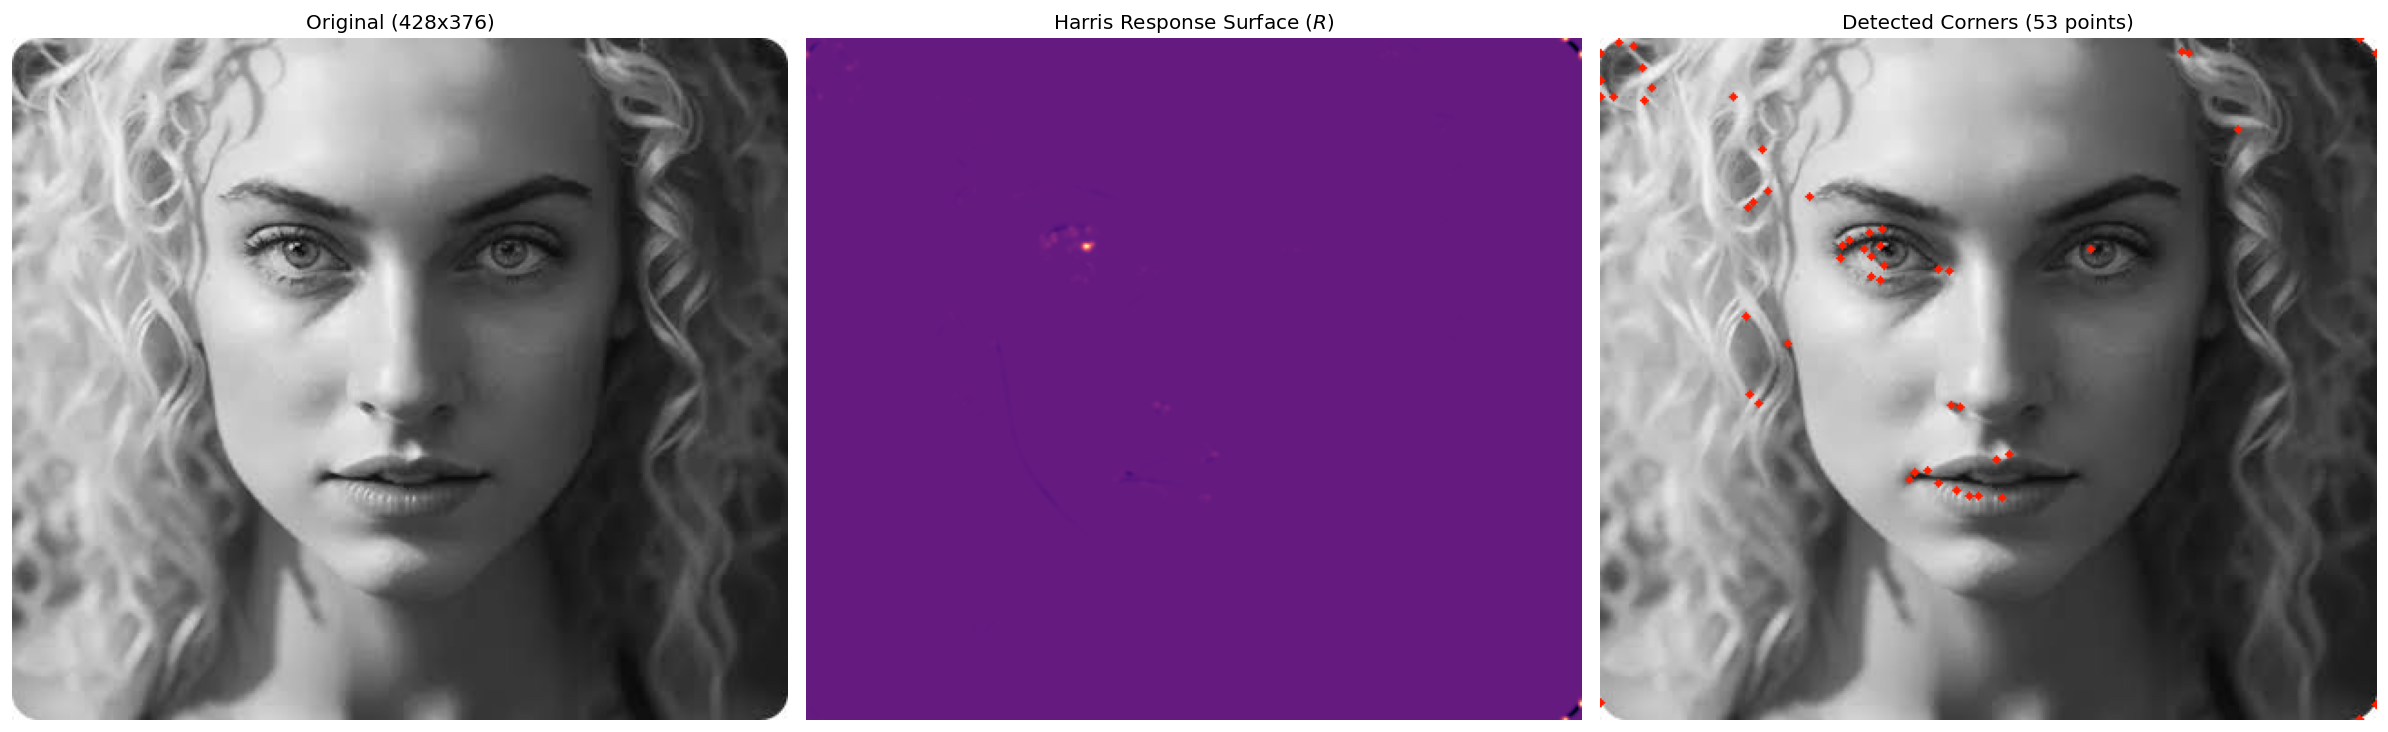

In [3]:
from google.colab import files

uploaded = files.upload()
for filename, content in uploaded.items():
    print(f"Processing uploaded image: {filename}")
    process_and_visualize(content, k=0.04, sigma=1.2, threshold_ratio=0.01, nms_size=5)